In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report
)
# Load the dataset
df = pd.read_csv("GHPR_dataset.csv")

# Inspect the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
display(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types and missing values:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (6052, 23)

Column names:


['SHA',
 'cbo',
 'wmc',
 'dit',
 'rfc',
 'lcom',
 'totalMethods',
 'totalFields',
 'nosi',
 'loc',
 'returnQty',
 'loopQty',
 'comparisonsQty',
 'tryCatchQty',
 'parenthesizedExpsQty',
 'stringLiteralsQty',
 'numbersQty',
 'assignmentsQty',
 'mathOperationsQty',
 'variablesQty',
 'maxNestedBlocks',
 'uniqueWordsQty',
 'defect']


First 5 rows:


,SHA,cbo,wmc,dit,rfc,lcom,totalMethods,totalFields,nosi,loc,...,tryCatchQty,parenthesizedExpsQty,stringLiteralsQty,numbersQty,assignmentsQty,mathOperationsQty,variablesQty,maxNestedBlocks,uniqueWordsQty,defect
0,7a955fd6c7de2bd912be544dcfe77f9173a7aa600,5,60,2,55,189,27,5,30,247,...,4,2,47,9,27,5,17,3,191,0
1,000f1ab4780fc9460975791c52597f7c04e15be70,3,10,1,1,9,7,4,1,38,...,0,0,0,22,4,0,4,2,69,0
2,000f1ab4780fc9460975791c52597f7c04e15be71,3,10,1,1,9,7,4,0,38,...,0,0,0,22,4,0,4,2,69,1
3,0024dbdd6ba3cc7797cc0b1ae537dcdc488c4c270,20,59,3,63,189,24,9,4,262,...,0,6,6,14,45,8,41,4,222,0
4,0024dbdd6ba3cc7797cc0b1ae537dcdc488c4c271,21,58,2,61,189,24,9,0,260,...,0,6,6,14,45,8,41,4,222,1



Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6052 entries, 0 to 6051
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   SHA                   6052 non-null   object
 1   cbo                   6052 non-null   int64 
 2   wmc                   6052 non-null   int64 
 3   dit                   6052 non-null   int64 
 4   rfc                   6052 non-null   int64 
 5   lcom                  6052 non-null   int64 
 6   totalMethods          6052 non-null   int64 
 7   totalFields           6052 non-null   int64 
 8   nosi                  6052 non-null   int64 
 9   loc                   6052 non-null   int64 
 10  returnQty             6052 non-null   int64 
 11  loopQty               6052 non-null   int64 
 12  comparisonsQty        6052 non-null   int64 
 13  tryCatchQty           6052 non-null   int64 
 14  parenthesizedExpsQty  6052 non-null   int64 
 15  string

In [13]:
# Check the distribution of the target
print(df["defect"].value_counts())
print("\nClass percentages:")
print(df["defect"].value_counts(normalize=True) * 100)

defect
0    3026
1    3026
Name: count, dtype: int64

Class percentages:
defect
0    50.0
1    50.0
Name: proportion, dtype: float64


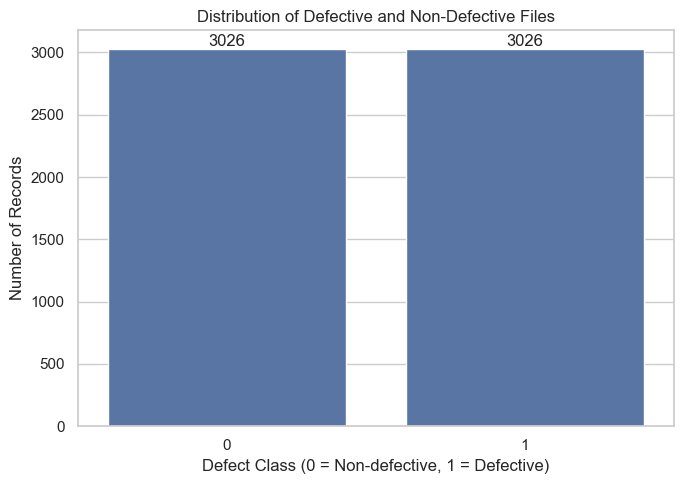

In [14]:

sns.set_theme(style="whitegrid")

TARGET = "defect"

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x=TARGET)

ax.set_title("Distribution of Defective and Non-Defective Files")
ax.set_xlabel("Defect Class (0 = Non-defective, 1 = Defective)")
ax.set_ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig("Distribution of Defective and Non-Defective Files", dpi=300, bbox_inches="tight")
plt.show()

The dataset is perfectly balanced, with exactly 3,026 non-defective

In [15]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values found.")
else:
    plt.figure(figsize=(10, 5))
    missing.plot(kind="bar")
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Values")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig("Missing Values", dpi=300, bbox_inches="tight")
    plt.show()

No missing values found.


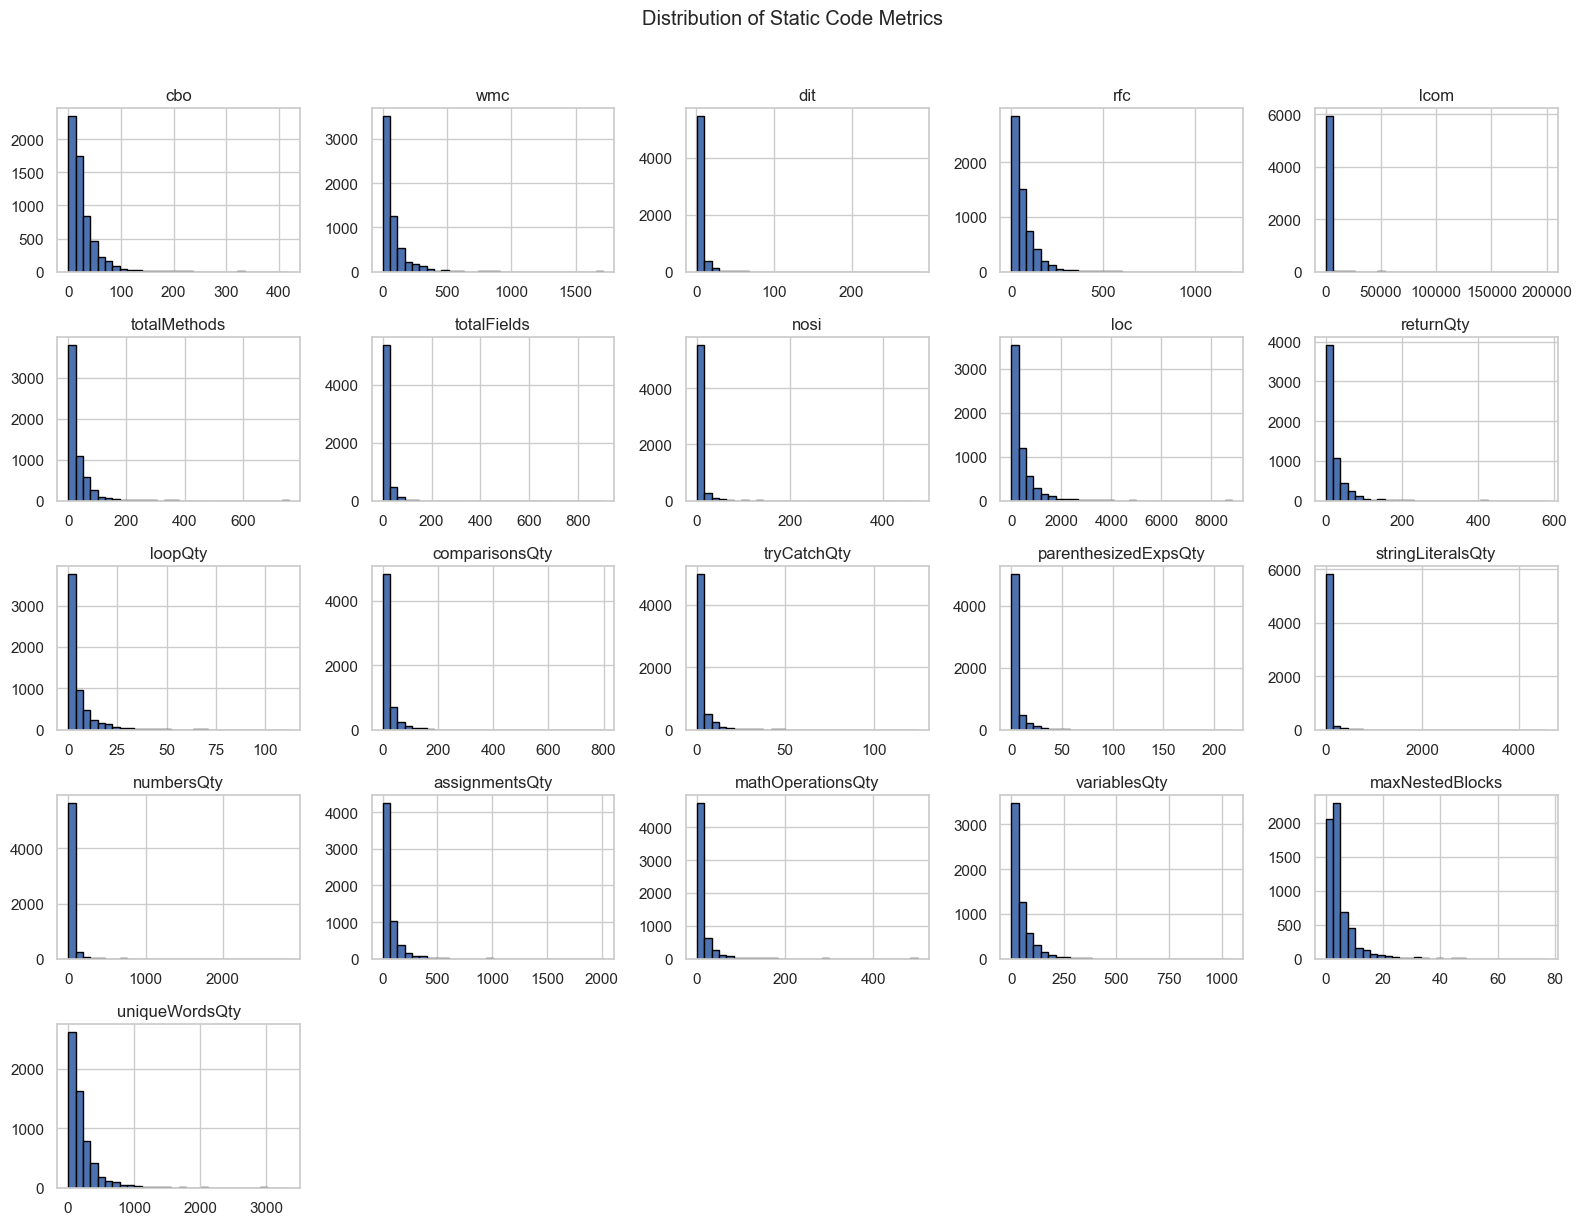

In [25]:

# Define the static code metrics used as input features
feature_cols = [
    "cbo", "wmc", "dit", "rfc", "lcom",
    "totalMethods", "totalFields", "nosi", "loc",
    "returnQty", "loopQty", "comparisonsQty",
    "tryCatchQty", "parenthesizedExpsQty",
    "stringLiteralsQty", "numbersQty", "assignmentsQty",
    "mathOperationsQty", "variablesQty", "maxNestedBlocks",
    "uniqueWordsQty"
]

# Visualize feature distributions
df[feature_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Static Code Metrics", y=1.02)
plt.tight_layout()
plt.savefig("static_code_metrics_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


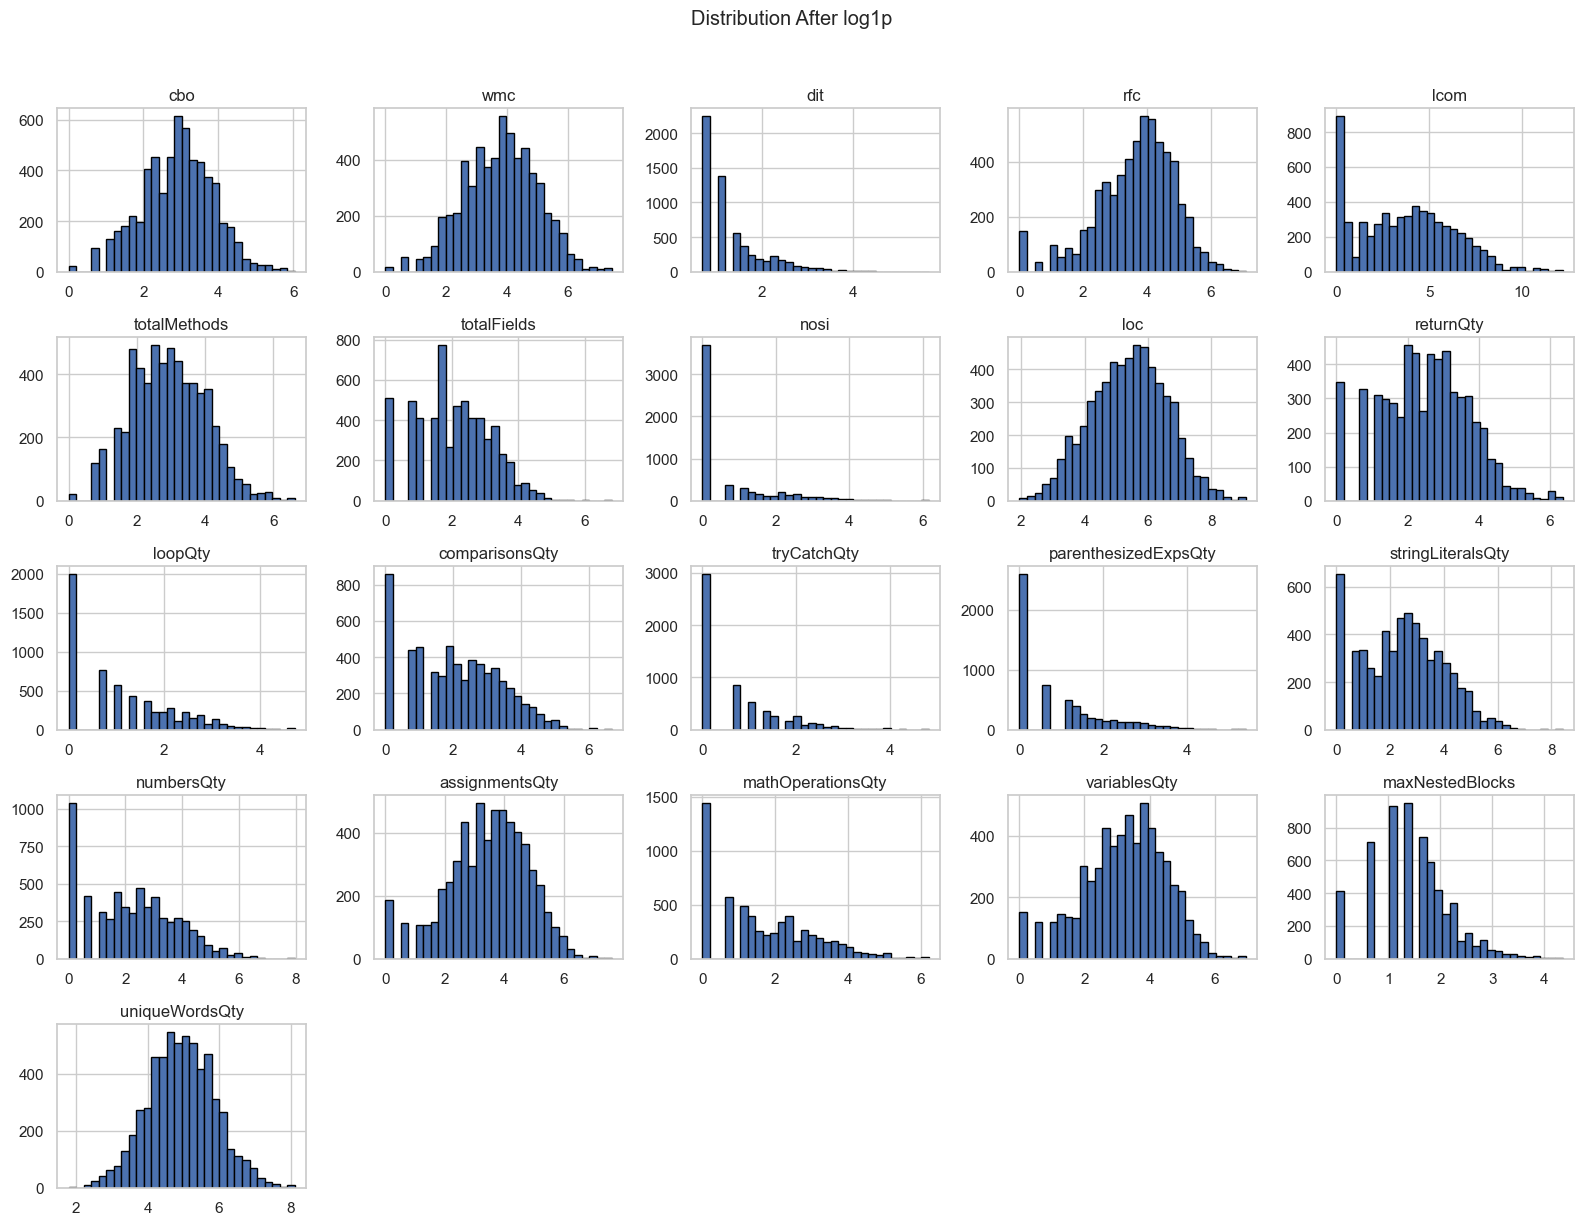

In [17]:
import numpy as np
import matplotlib.pyplot as plt

df_log = np.log1p(df[feature_cols])
df_log.hist(bins=30, figsize=(16, 12), edgecolor="black")
plt.suptitle("Distribution After log1p", y=1.02)
plt.tight_layout()
plt.savefig("Distribution_After_log1p.png", dpi=300, bbox_inches="tight")
plt.show()

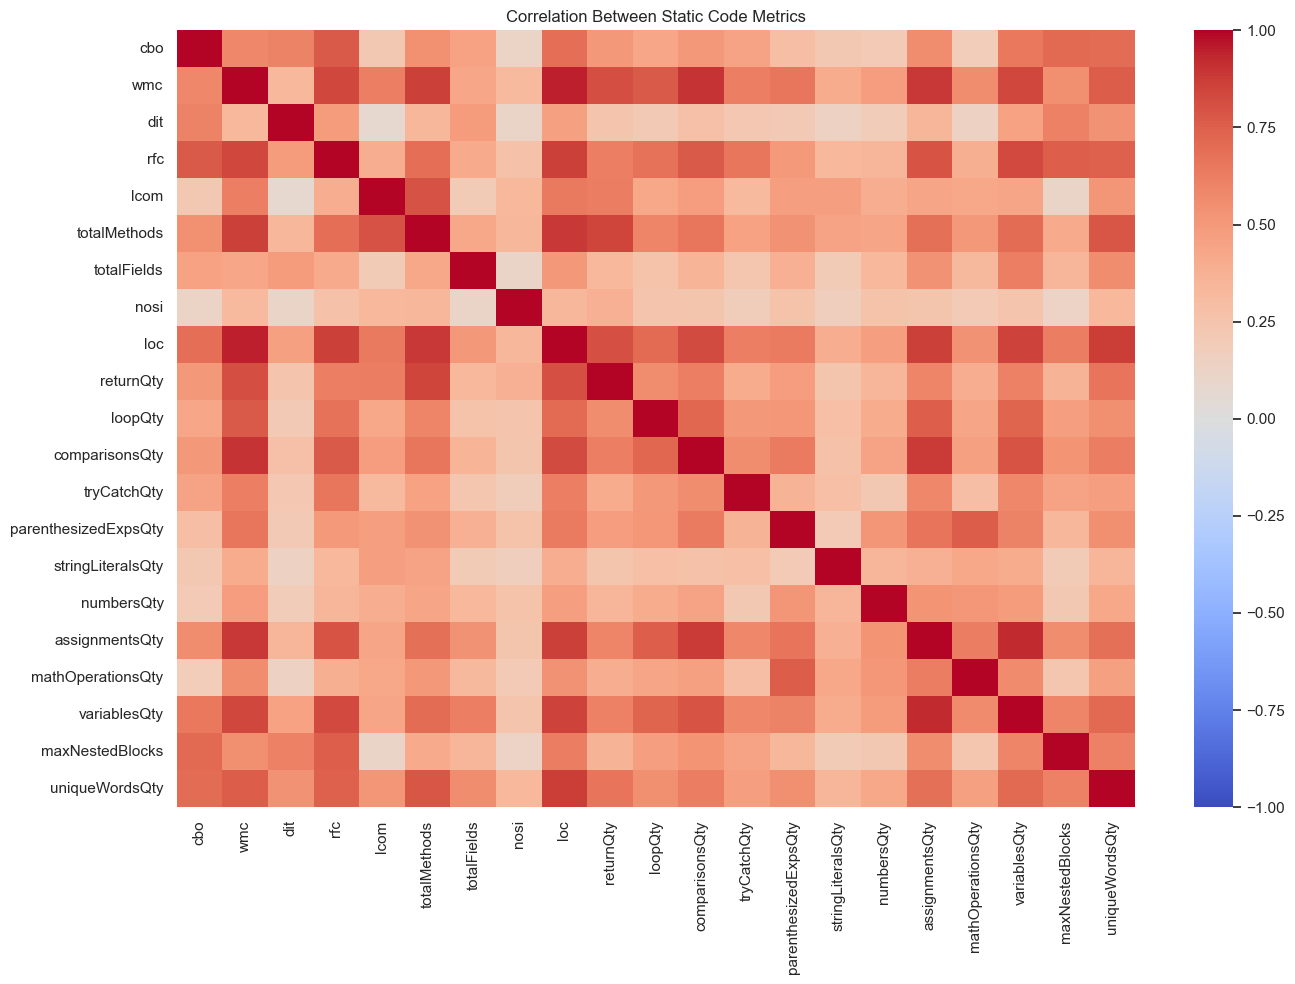

In [18]:
corr = df[feature_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Static Code Metrics")
plt.tight_layout()
plt.savefig("Correlation Between Static Code Metrics", dpi=300, bbox_inches="tight")
plt.show()

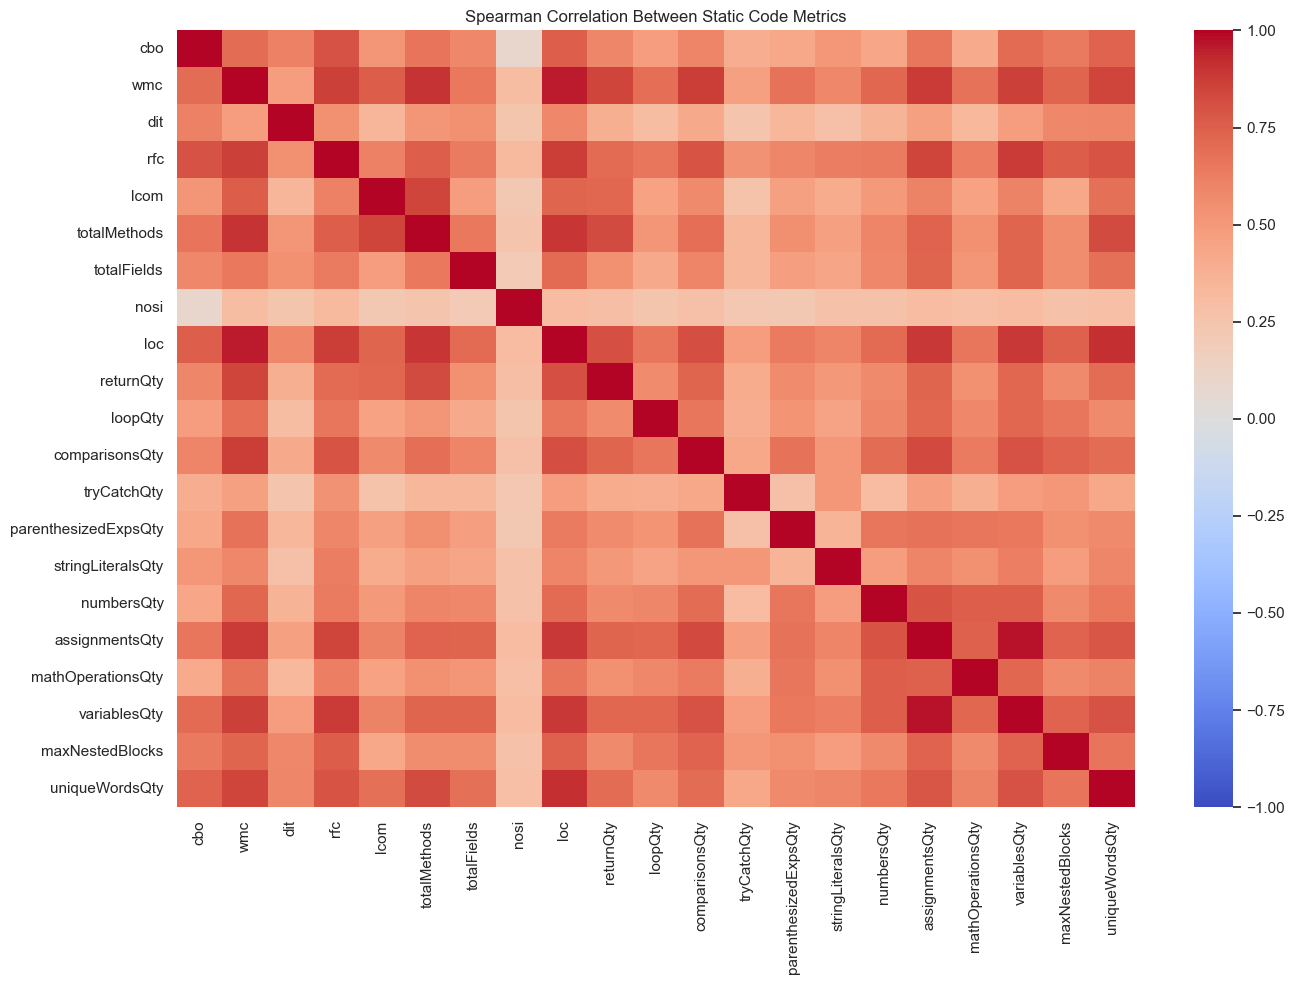

In [19]:
corr = df[feature_cols].corr(method="spearman")

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Between Static Code Metrics")
plt.tight_layout()
plt.savefig("Spearman_Correlation_Between_Static_Code_Metrics.png", dpi=300, bbox_inches="tight")
plt.show()

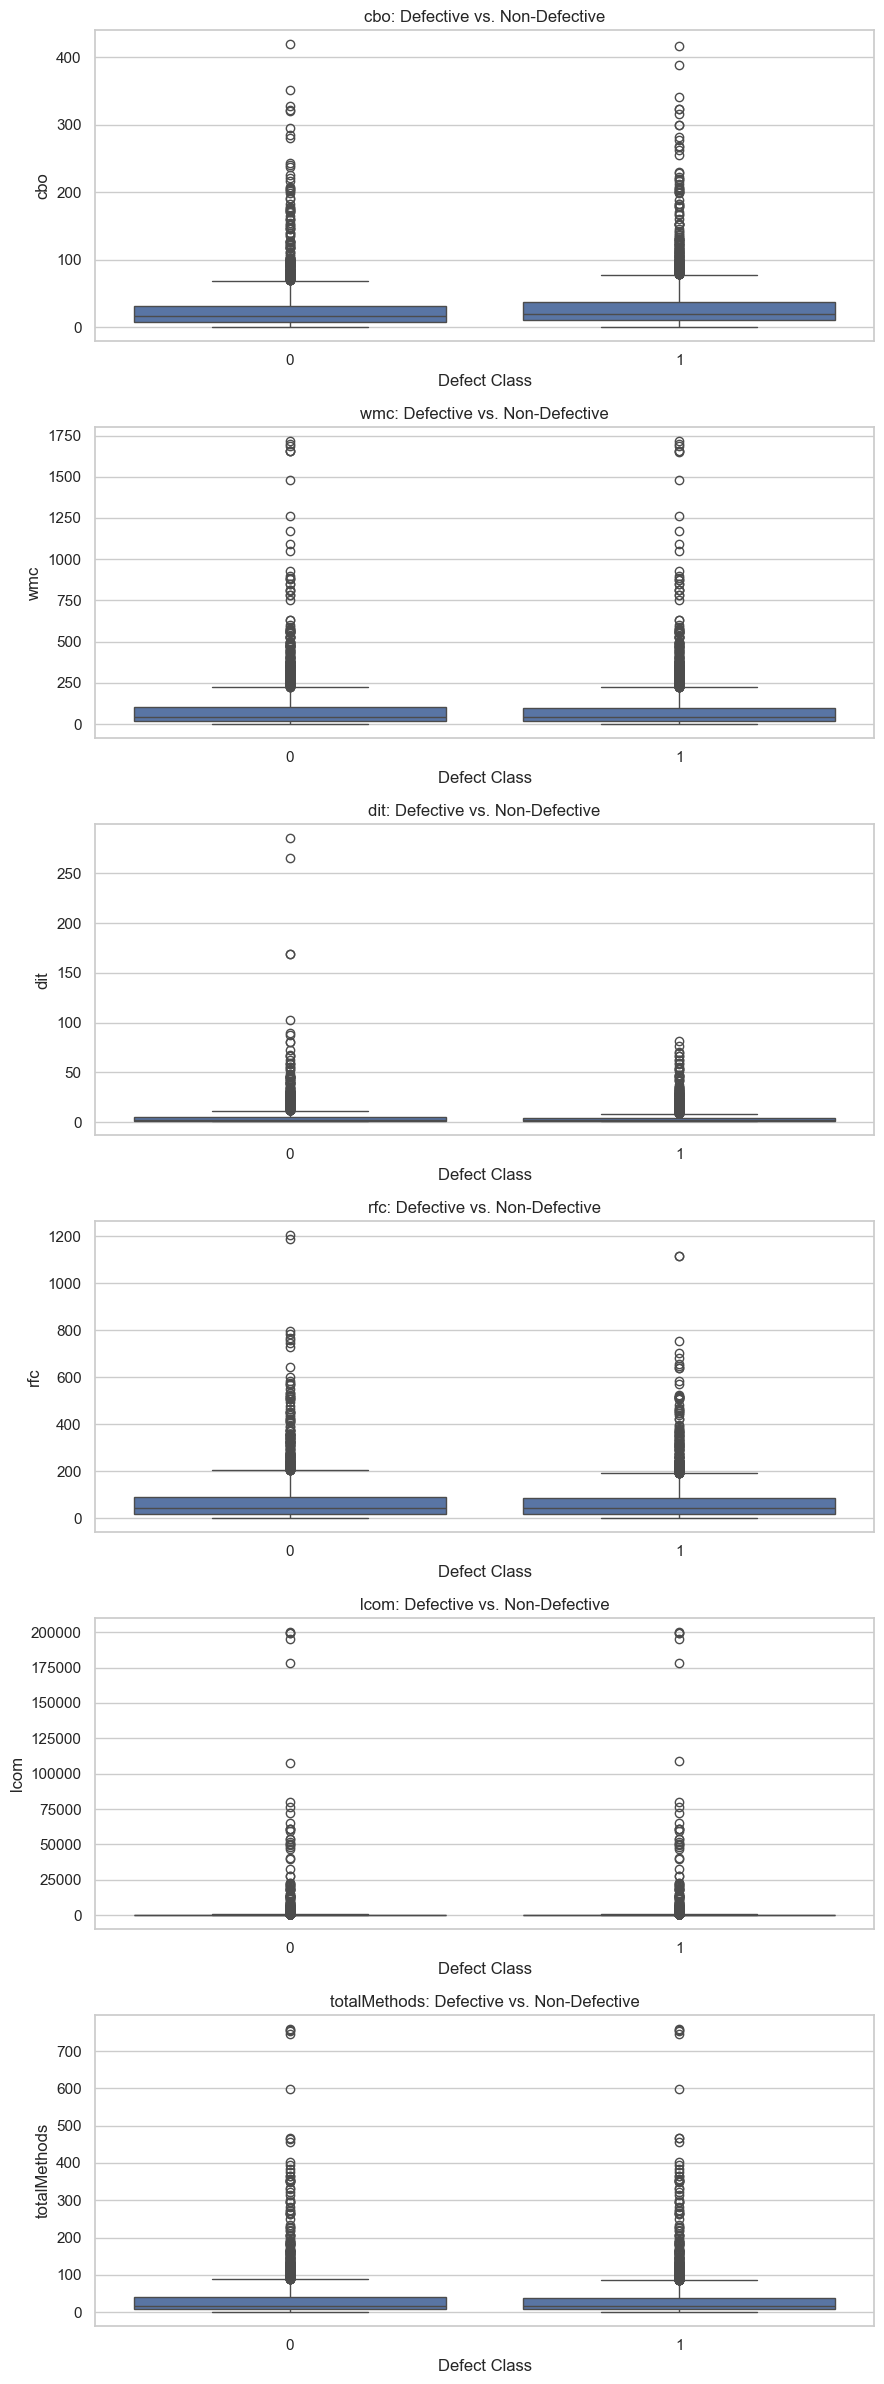

In [20]:
# Select up to six metrics for easier comparison
selected_features = feature_cols[:6]

fig, axes = plt.subplots(
    nrows=len(selected_features),
    ncols=1,
    figsize=(9, 4 * len(selected_features))
)

axes = np.atleast_1d(axes)

for ax, col in zip(axes, selected_features):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax)
    ax.set_title(f"{col}: Defective vs. Non-Defective")
    ax.set_xlabel("Defect Class")

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Conclusion: 
The static code metrics dataset contains roughly 6,000 classes described by 21 numeric features. All of them are strongly right-skewed with extreme outliers (for example, lcom reaches 200,000), and many are zero-inflated (nosi, tryCatchQty, loopQty, parenthesizedExpsQty, among others). A log1p transformation substantially reduced the skew, producing near-bell-shaped distributions for most size and complexity metrics, though dit and lcom remained imperfect. The correlation analysis showed no negative relationships but revealed a large cluster of highly correlated size and complexity metrics (wmc, loc, rfc, totalMethods, assignmentsQty, variablesQty, comparisonsQty, uniqueWordsQty), with Spearman correlations stronger than Pearson, which confirms that outliers were masking part of the relationships. This multicollinearity must be handled with correlation-based filtering and VIF before fitting a linear model. The box plots show that the defective and non-defective classes have very similar distributions for most features, with cbo showing the clearest separation, so only modest predictive performance should be expected. We have balance classes, No duplicate rows, and No missing values and all preprocessing steps (scaling, feature removal) must be fitted on the training split only to avoid data leakage.